In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pickle as pkl
import sys

sys.path.insert(0, '/exp/icarus/app/users/micarrig/gundam/gundam-icarus/configsNue')
from makePrettyPlots import stamp_ax, POT_DEFAULT  # ICARUS Work-in-Progress + POT watermark


Welcome to JupyROOT 6.28/12


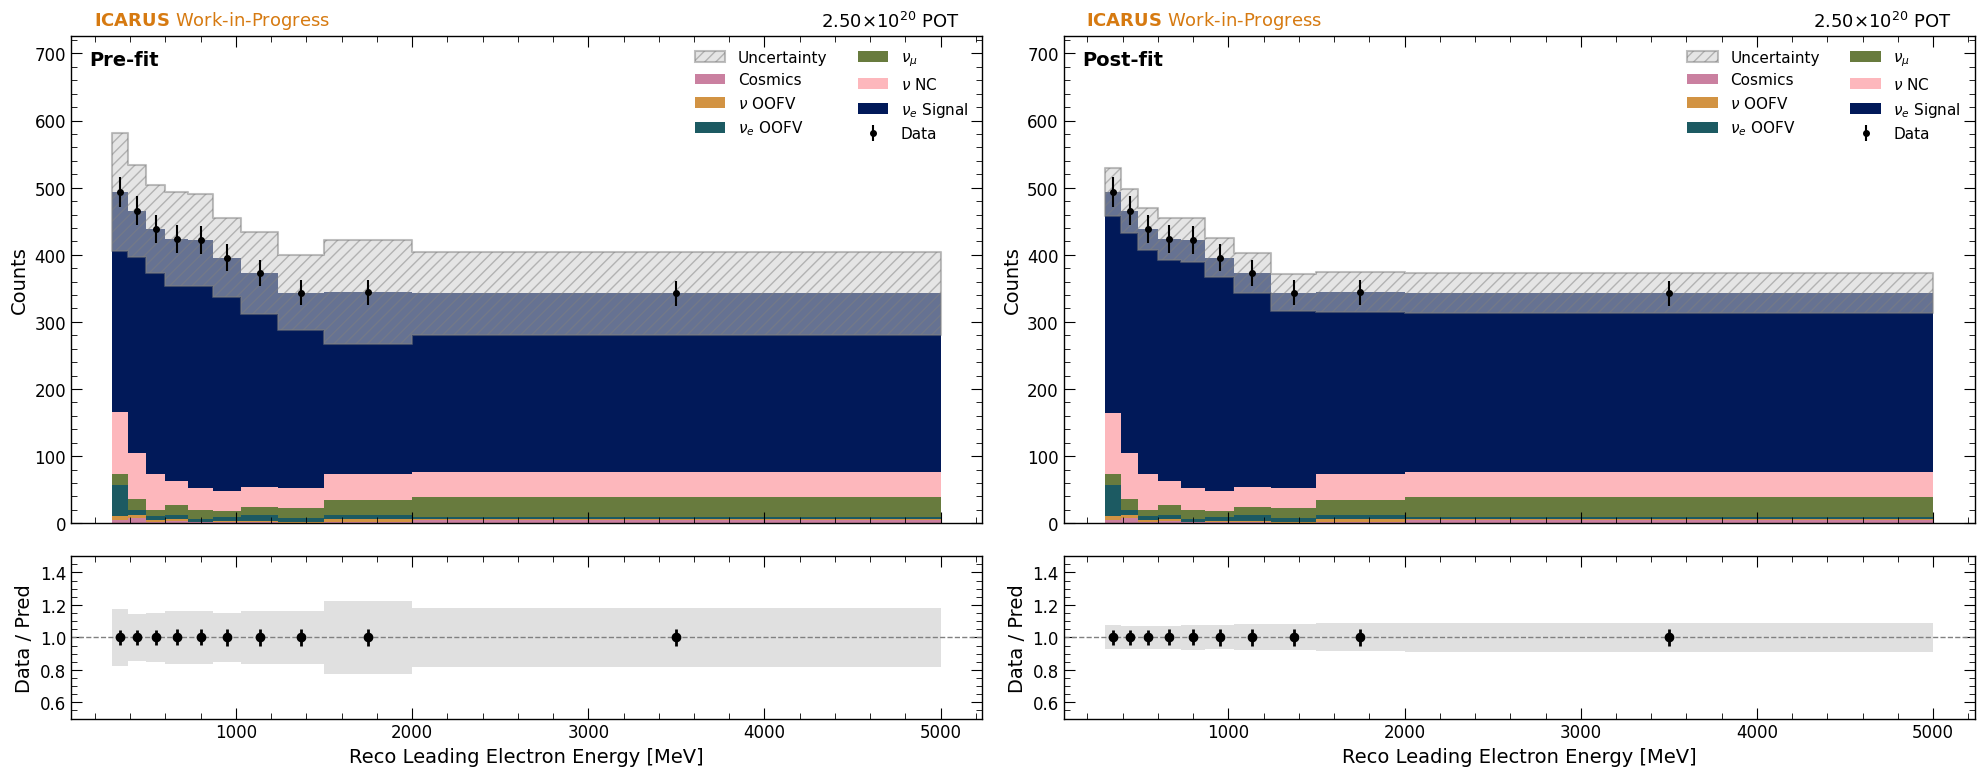

In [10]:
with open('/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/EleE/v31/asimov/pkl/pre_post_fit_comparison.pkl', 'rb') as f:
    pre_post_fit = pkl.load(f)

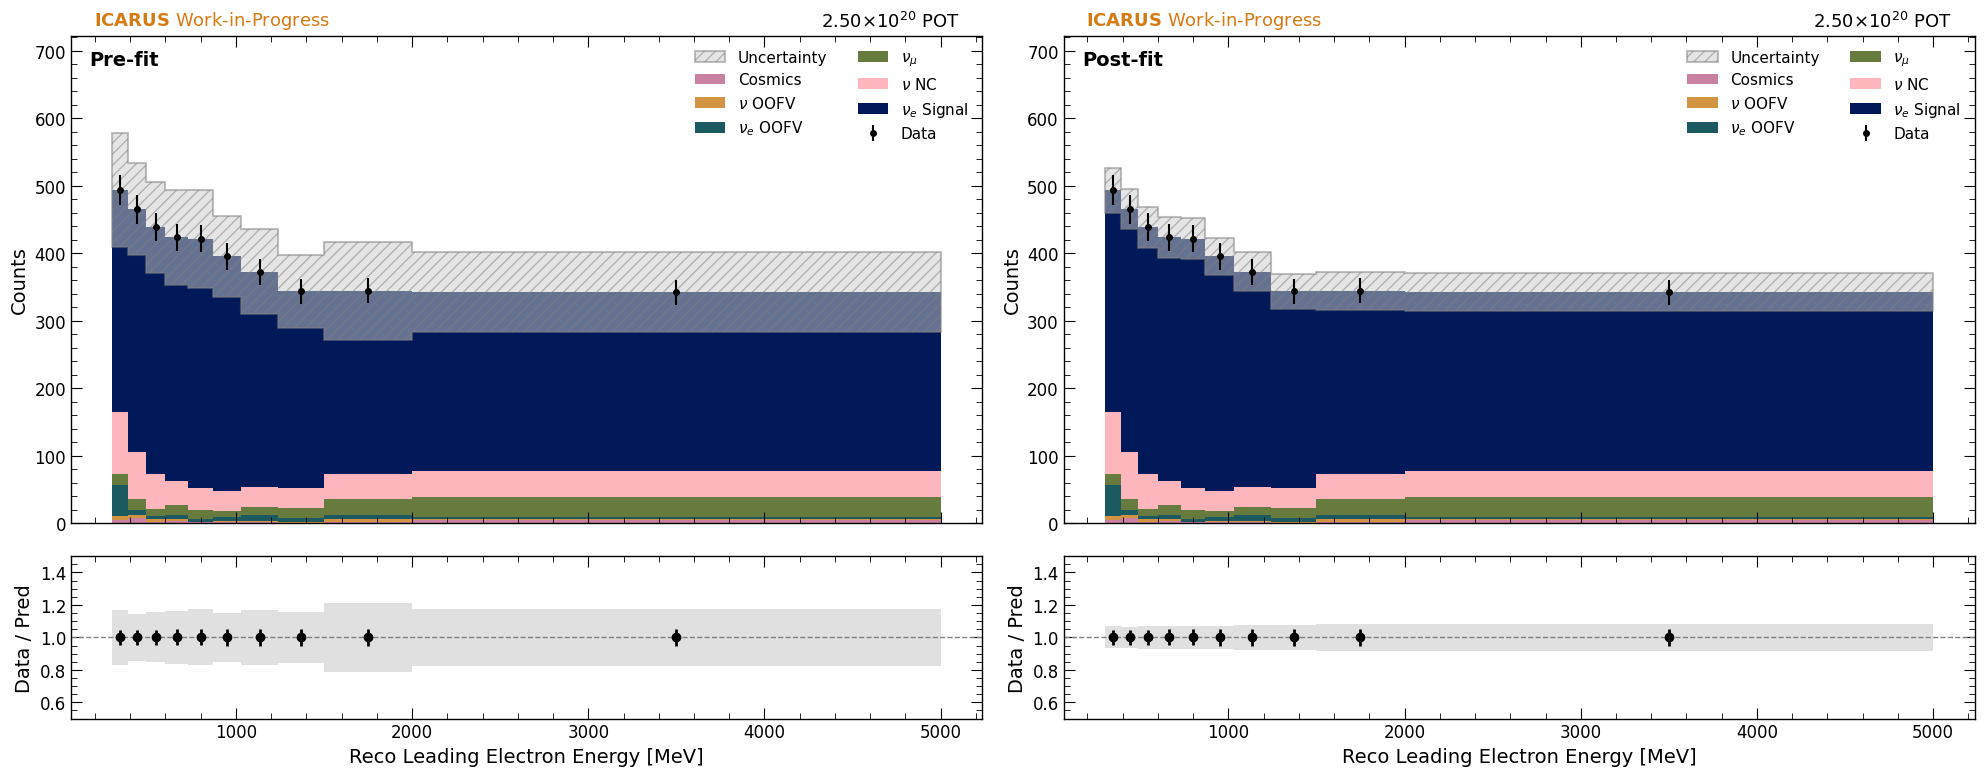

In [11]:
with open('/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/EleE/v31/asimov_sb/pkl/pre_post_fit_comparison.pkl', 'rb') as f:
    pre_post_fit = pkl.load(f)

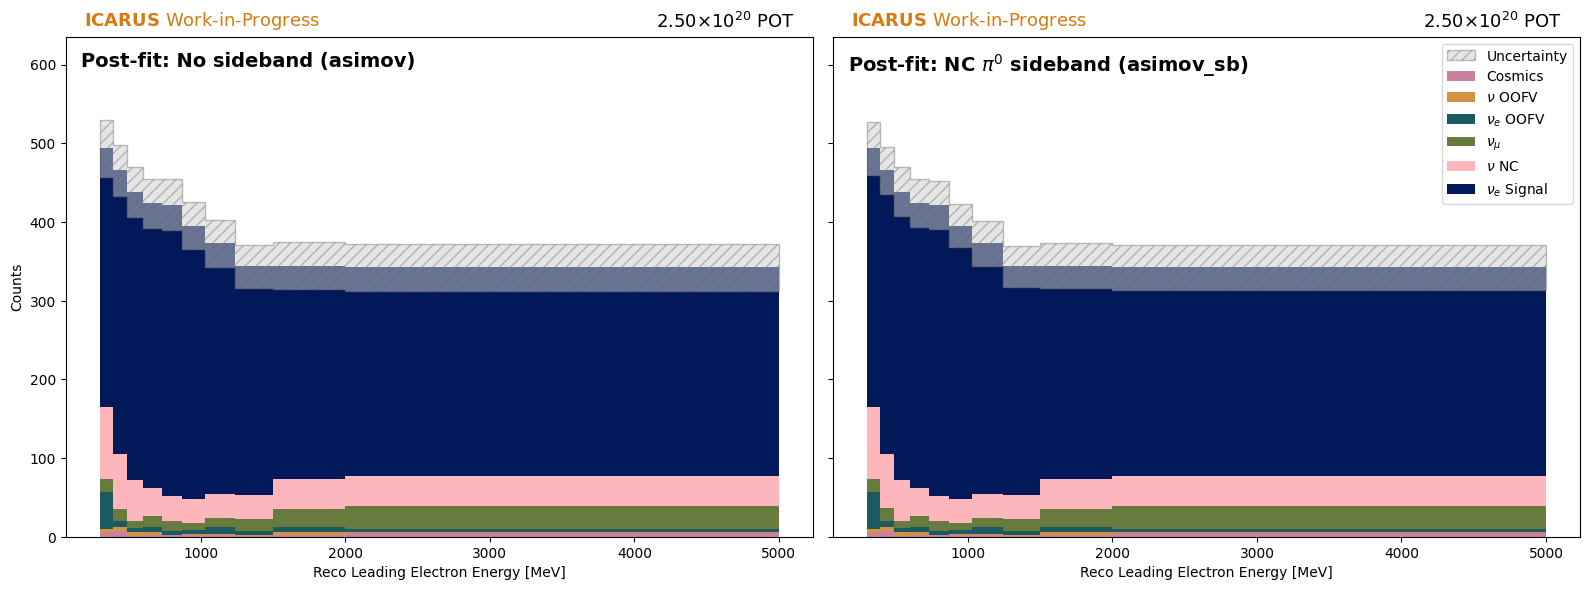

      bin [MeV] |     pred      err    frac |     pred      err    frac | sb/nosb
                |    --- no sideband ---    |  --- NC pi0 sideband ---  |
   300-390      |    493.5     36.1    7.3% |    493.5     33.4    6.8% |   0.924
   390-490      |    465.6     32.7    7.0% |    465.6     29.4    6.3% |   0.900
   490-600      |    438.6     31.9    7.3% |    438.6     30.8    7.0% |   0.966
   600-730      |    423.6     30.8    7.3% |    423.6     30.5    7.2% |   0.989
   730-870      |    421.9     32.4    7.7% |    422.0     30.4    7.2% |   0.938
   870-1030     |    395.5     29.3    7.4% |    395.5     27.9    7.1% |   0.953
  1030-1240     |    372.9     29.6    7.9% |    372.9     28.5    7.6% |   0.962
  1240-1500     |    343.7     27.4    8.0% |    343.7     26.3    7.6% |   0.958
  1500-2000     |    344.4     29.8    8.6% |    344.3     28.6    8.3% |   0.961
  2000-5000     |    342.5     29.9    8.7% |    342.5     28.4    8.3% |   0.950


In [12]:
from matplotlib.container import BarContainer

base = '/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/EleE/v31'
files = {
    'No sideband (asimov)':             f'{base}/asimov/pkl/pre_post_fit_comparison.pkl',
    'NC $\\pi^0$ sideband (asimov_sb)': f'{base}/asimov_sb/pkl/pre_post_fit_comparison.pkl',
}

def extract_postfit(fig, ax_index=1):
    """Pull the stacked components and the uncertainty band out of the post-fit panel."""
    ax = fig.axes[ax_index]
    stacks = []
    for c in ax.containers:
        if isinstance(c, BarContainer):
            stacks.append(dict(label=c.get_label(),
                               color=c.patches[0].get_facecolor(),
                               heights=np.array([p.get_height() for p in c.patches])))
    p0 = ax.containers[0].patches
    left = np.array([p.get_x() for p in p0])
    width = np.array([p.get_width() for p in p0])
    edges = np.r_[left, left[-1] + width[-1]]
    total = np.sum([s['heights'] for s in stacks], axis=0)

    # band is fill_between(step='post'): each bin has a horizontal lower and upper segment
    band = next(c for c in ax.collections if c.get_label() == 'Uncertainty')
    v = band.get_paths()[0].vertices
    upper = np.empty(len(total))
    for i in range(len(total)):
        ys = [v[j, 1] for j in range(len(v) - 1)
              if v[j, 1] == v[j + 1, 1]
              and {round(v[j, 0], 6), round(v[j + 1, 0], 6)} == {round(edges[i], 6), round(edges[i + 1], 6)}]
        upper[i] = max(ys)
    err = upper - total
    return dict(edges=edges, centers=left + width / 2, width=width, total=total, err=err, stacks=stacks)

results = {}
for name, path in files.items():
    with open(path, 'rb') as f:
        fig_in = pkl.load(f)
    results[name] = extract_postfit(fig_in)
    plt.close(fig_in)

# --- side-by-side post-fit plots ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    bottom = np.zeros_like(r['total'])
    for s in r['stacks']:
        ax.bar(r['centers'], s['heights'], width=r['width'], bottom=bottom,
               color=s['color'], label=s['label'])
        bottom += s['heights']
    lo = np.maximum(0, r['total'] - r['err'])
    hi = r['total'] + r['err']
    ax.fill_between(r['edges'], np.r_[lo, lo[-1]], np.r_[hi, hi[-1]], step='post',
                    facecolor='0.8', edgecolor='gray', hatch='///', alpha=0.5, label='Uncertainty')
    ax.text(0.02, 0.97, f'Post-fit: {name}', transform=ax.transAxes,
            ha='left', va='top', fontsize=14, fontweight='bold')
    ax.set_xlabel('Reco Leading Electron Energy [MeV]')
axes[0].set_ylabel('Counts')
axes[1].legend(loc='upper right')
ymax = max(np.max(r['total'] + r['err']) for r in results.values())
axes[0].set_ylim(0, 1.2 * ymax)  # headroom for the title (y is shared)
for ax in axes:
    stamp_ax(ax, POT_DEFAULT)
fig.tight_layout()
plt.show()

# --- per-bin errors ---
(n1, r1), (n2, r2) = results.items()
assert np.allclose(r1['edges'], r2['edges'])
print(f"{'bin [MeV]':>15} | {'pred':>8} {'err':>8} {'frac':>7} | {'pred':>8} {'err':>8} {'frac':>7} | {'sb/nosb':>7}")
print(f"{'':>15} | {'--- no sideband ---':^25} | {'--- NC pi0 sideband ---':^25} |")
for i in range(len(r1['total'])):
    f1 = r1['err'][i] / r1['total'][i]
    f2 = r2['err'][i] / r2['total'][i]
    print(f"{r1['edges'][i]:6.0f}-{r1['edges'][i+1]:<6.0f}   | "
          f"{r1['total'][i]:8.1f} {r1['err'][i]:8.1f} {100*f1:6.1f}% | "
          f"{r2['total'][i]:8.1f} {r2['err'][i]:8.1f} {100*f2:6.1f}% | {r2['err'][i]/r1['err'][i]:7.3f}")

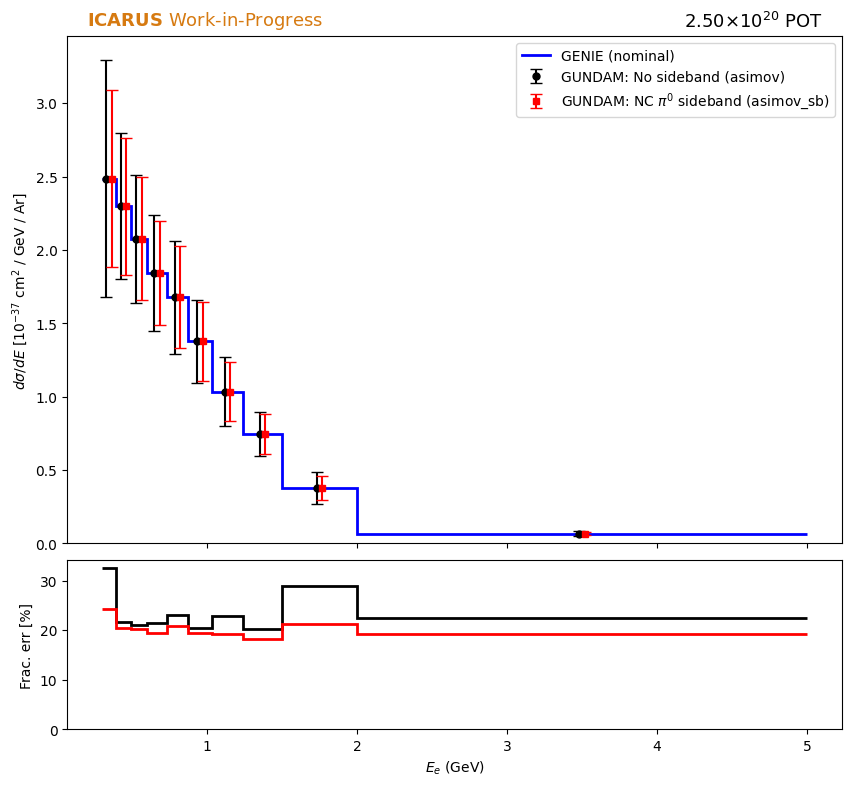

units: $d\sigma/dE$ [$10^{-37}$ cm$^{2}$ / GeV / Ar]
    bin [GeV] |    xsec     err    frac |    xsec     err    frac | sb/nosb
              |   --- no sideband ---   | --- NC pi0 sideband --- |
 0.30-0.39    |   2.484   0.807   32.5% |   2.484   0.603   24.3% |   0.747
 0.39-0.49    |   2.297   0.498   21.7% |   2.297   0.468   20.4% |   0.939
 0.49-0.60    |   2.075   0.436   21.0% |   2.075   0.420   20.2% |   0.963
 0.60-0.73    |   1.842   0.395   21.5% |   1.842   0.357   19.4% |   0.904
 0.73-0.87    |   1.677   0.386   23.0% |   1.678   0.348   20.8% |   0.902
 0.87-1.03    |   1.377   0.282   20.5% |   1.377   0.267   19.4% |   0.948
 1.03-1.24    |   1.034   0.236   22.9% |   1.034   0.199   19.3% |   0.844
 1.24-1.50    |   0.744   0.151   20.2% |   0.744   0.136   18.2% |   0.901
 1.50-2.00    |   0.377   0.109   28.9% |   0.377   0.080   21.2% |   0.733
 2.00-5.00    |   0.067   0.015   22.4% |   0.067   0.013   19.3% |   0.863


In [13]:
xsec_files = {
    'No sideband (asimov)':             f'{base}/asimov/pkl/genie_gundam_xsec_comparison.pkl',
    'NC $\\pi^0$ sideband (asimov_sb)': f'{base}/asimov_sb/pkl/genie_gundam_xsec_comparison.pkl',
}

def extract_xsec(fig):
    """GUNDAM points/errors and the GENIE step histogram from the top panel (values in the plot's 10^N units)."""
    ax = fig.axes[0]
    eb = next(c for c in ax.containers if c.get_label() == 'GUNDAM')
    y = np.asarray(eb.lines[0].get_ydata(), dtype=float)
    xseg, yseg = [c.get_segments() for c in eb.lines[2]]
    edges = np.r_[[s[0][0] for s in xseg], xseg[-1][1][0]]
    yerr = np.array([(s[1][1] - s[0][1]) / 2 for s in yseg])

    # GENIE step histogram: take the horizontal segment spanning each bin
    genie = next(p for p in ax.patches if p.get_label().startswith('GENIE'))
    v = genie.get_xy()
    ref = np.empty(len(y))
    for i in range(len(y)):
        ref[i] = max(v[j, 1] for j in range(len(v) - 1)
                     if v[j, 1] == v[j + 1, 1]
                     and np.isclose(min(v[j, 0], v[j + 1, 0]), edges[i])
                     and np.isclose(max(v[j, 0], v[j + 1, 0]), edges[i + 1]))
    return dict(edges=edges, centers=(edges[:-1] + edges[1:]) / 2, y=y, yerr=yerr, ref=ref,
                ref_label=genie.get_label(), ylabel=ax.get_ylabel(), xlabel=fig.axes[1].get_xlabel())

xres = {}
for name, path in xsec_files.items():
    with open(path, 'rb') as f:
        fig_in = pkl.load(f)
    xres[name] = extract_xsec(fig_in)
    plt.close(fig_in)

# --- overlay: GENIE + GUNDAM with and without sideband, fractional errors below ---
r0 = xres[next(iter(xres))]
edges, centers, widths = r0['edges'], r0['centers'], np.diff(r0['edges'])
styles = [dict(color='black', marker='o'), dict(color='red', marker='s')]
offsets = [-0.2, 0.2]   # x shift as a fraction of the narrowest bin, so the two sets of bars don't overlap

fig, (ax, ax_frac) = plt.subplots(2, 1, figsize=(10, 9), sharex=True,
                                  gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05})
ax.stairs(r0['ref'], edges, color='blue', linewidth=2, baseline=None, label=r0['ref_label'])
for (name, r), st, off in zip(xres.items(), styles, offsets):
    x = centers + off * widths.min()
    ax.errorbar(x, r['y'], yerr=r['yerr'], fmt=st['marker'], color=st['color'],
                capsize=4, markersize=5, label=f'GUNDAM: {name}')
    ax_frac.stairs(100 * r['yerr'] / r['y'], edges, color=st['color'], linewidth=2, baseline=None)
ax.set_ylabel(r0['ylabel'])
ax.set_ylim(bottom=0)
ax.legend(loc='upper right')
ax_frac.set_ylabel('Frac. err [%]')
ax_frac.set_xlabel(r0['xlabel'])
ax_frac.set_ylim(bottom=0)
stamp_ax(ax, POT_DEFAULT)
plt.show()

# --- per-bin cross-section errors (units of the plot's y axis) ---
(n1, x1), (n2, x2) = xres.items()
assert np.allclose(x1['edges'], x2['edges'])
print('units:', x1['ylabel'])
print(f"{'bin [GeV]':>13} | {'xsec':>7} {'err':>7} {'frac':>7} | {'xsec':>7} {'err':>7} {'frac':>7} | {'sb/nosb':>7}")
print(f"{'':>13} | {'--- no sideband ---':^23} | {'--- NC pi0 sideband ---':^23} |")
for i in range(len(x1['y'])):
    f1 = x1['yerr'][i] / x1['y'][i]
    f2 = x2['yerr'][i] / x2['y'][i]
    print(f"{x1['edges'][i]:5.2f}-{x1['edges'][i+1]:<5.2f}   | "
          f"{x1['y'][i]:7.3f} {x1['yerr'][i]:7.3f} {100*f1:6.1f}% | "
          f"{x2['y'][i]:7.3f} {x2['yerr'][i]:7.3f} {100*f2:6.1f}% | {x2['yerr'][i]/x1['yerr'][i]:7.3f}")